# HWK 4- EVALUAITON

In [1]:
import os
import urllib.request


print("Current working directory:", os.getcwd())

# Create data directory if it doesn't exist
if not os.path.exists('data'):
    os.makedirs('data')
    print("Created 'data' directory")

# Download the file using urllib instead of wget
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
output_path = 'data/course_lead_scoring.csv'

print(f"\nDownloading from {url}")
urllib.request.urlretrieve(url, output_path)

# Verify the file was downloaded
if os.path.exists(output_path):
    print(f"\nFile successfully downloaded to {output_path}")
    print("File size:", os.path.getsize(output_path), "bytes")

Current working directory: /Users/foroghakbari/Zoomcamp/ml_course/zoomcamp_ml/evaluation


File successfully downloaded to data/course_lead_scoring.csv
File size: 278746 bytes



### Data preparation

* Check if the missing values are presented in the features.
* If there are missing values:
    * For categorical features, replace them with 'NA'
    * For numerical features, replace with with 0.0 


Split the data into 3 parts with these exact calls:

```python
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
```



In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
df = pd.read_csv('data/course_lead_scoring.csv')

In [3]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [4]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [5]:
#fill NAs
# Create a fill values dictionary
fill_dict = {
    col: 0.0 if pd.api.types.is_numeric_dtype(dtype) else 'NA'
    for col, dtype in df.dtypes.items()
}

# Apply fillna in one step
df = df.fillna(value=fill_dict)


In [6]:
# Total missing values per column
print(df.isna().sum())

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


In [7]:
#hist of target variab

In [8]:
# Identify categorical and numerical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
if 'converted' in categorical_cols:
    categorical_cols.remove('converted')
    
numerical_cols = df.select_dtypes(include=['number']).columns.tolist()
if 'converted' in numerical_cols:
    numerical_cols.remove('converted')

print("\nCategorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

/var/folders/yp/fcwsrmjd6fd_161hmt7py7l00000gn/T/ipykernel_1030/928721650.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns.tolist()



Categorical columns: ['lead_source', 'industry', 'employment_status', 'location']
Numerical columns: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


In [9]:
# Split data into train, validation, and test sets (60/20/20)
# First split: 80% (train+val) and 20% (test)
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

# Second split: 75% of 80% = 60% (train) and 25% of 80% = 20% (val)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)


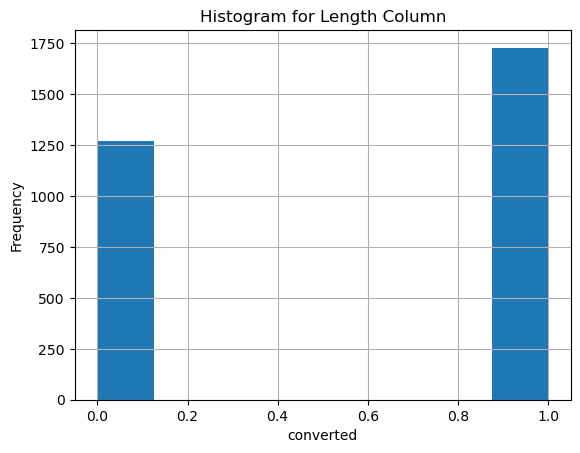

In [12]:

hist = df_train['converted'].hist(bins=8)

# Adding title and labels
plt.title('Histogram for Length Column')
plt.xlabel('converted')
plt.ylabel('Frequency')

# Display the histogram
plt.show()

In [ ]:

hist = df_train['converted'].hist(bins=8)

# Adding title and labels
plt.title('Histogram for Length Column')
plt.xlabel('converted')
plt.ylabel('Frequency')

# Display the histogram
plt.show()

In [14]:
numerical_cols

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

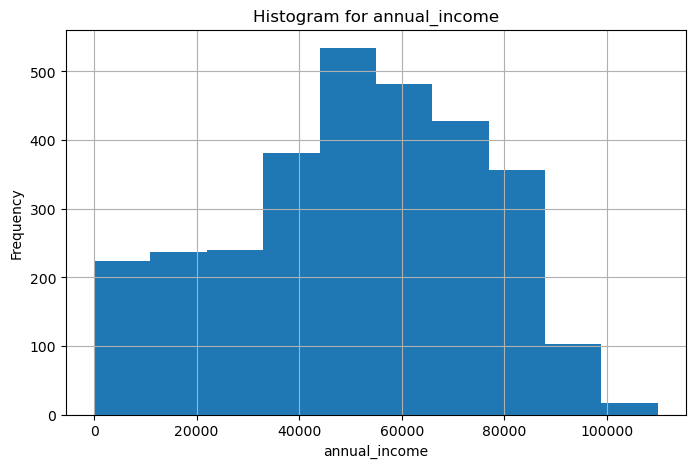

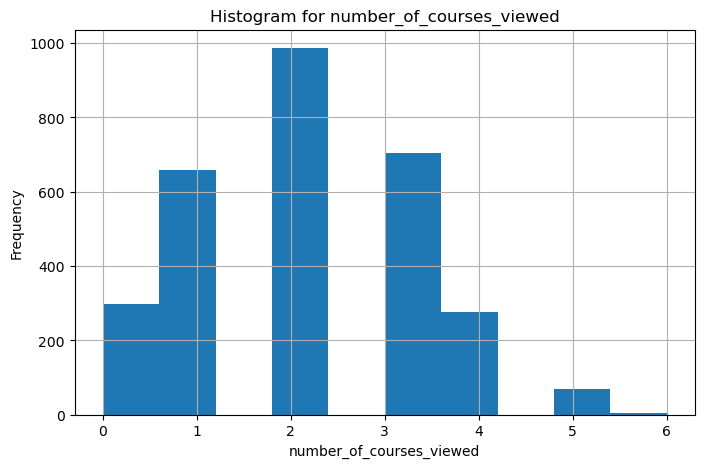

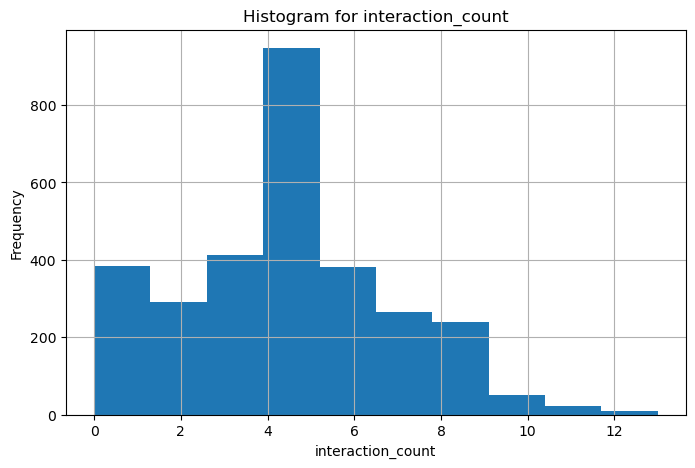

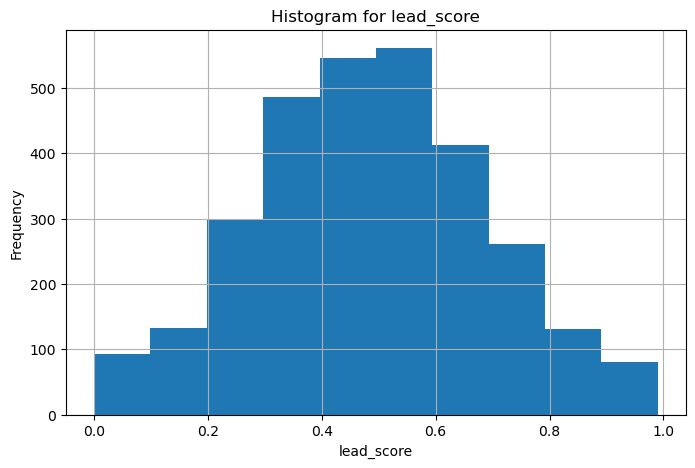

In [17]:


# Create a histogram for each numerical column
for col in numerical_cols:
    plt.figure(figsize=(8, 5))
    
    df_train[col].hist(bins=10)
    
    plt.title(f'Histogram for {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    
    plt.show()


In [25]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values

print(np.unique(y_train))

y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

[0 1]


In [32]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical_cols + numerical_cols].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')

In [33]:
val_dict = df_val[categorical_cols + numerical_cols].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
converted = (y_pred >= 0.5)
(y_val == converted).mean()

0.651

In [36]:
from sklearn.metrics import accuracy_score

In [37]:
thresholds = np.linspace(0, 1, 21)

scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f' % (t, score))
    scores.append(score)

0.00 0.586
0.05 0.586
0.10 0.586
0.15 0.586
0.20 0.586
0.25 0.586
0.30 0.597
0.35 0.613
0.40 0.625
0.45 0.640
0.50 0.651
0.55 0.661
0.60 0.681
0.65 0.669
0.70 0.643
0.75 0.590
0.80 0.530
0.85 0.468
0.90 0.432
0.95 0.416
1.00 0.414


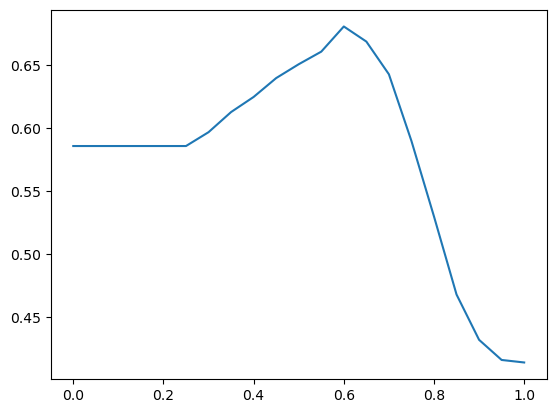

In [38]:
plt.plot(thresholds, scores)

In [40]:
from collections import Counter

In [41]:
Counter(y_pred >= 1.0)

Counter({False: 1000})

In [42]:
1 - y_val.mean()

0.41400000000000003

### Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables. 

Let's do that

* For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
* Use the training dataset for that


If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. `-df_train['balance']`)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

In [28]:
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, f1_score


In [21]:
numerical_cols

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [22]:
from sklearn.feature_extraction import DictVectorizer

In [45]:
from sklearn.metrics import roc_auc_score

numerical_cols = [
    'annual_income',
    'number_of_courses_viewed',
    'interaction_count',
    'lead_score'
]

auc_scores = {}

for numeric_feature in numerical_cols:
    feature = df_train[numeric_feature].values
    
    auc = roc_auc_score(y_train, feature)

    # If AUC < 0.5, reverse the direction
    if auc < 0.5:
        auc = roc_auc_score(y_train, -feature)

    auc_scores[numeric_feature] = auc

best_feature = max(auc_scores, key=auc_scores.get)

print("AUC scores:")
for feature, auc in auc_scores.items():
    print(f"{feature}: {auc:.4f}")

print(f"\nBest feature: {best_feature}")
print(f"Best AUC: {auc_scores[best_feature]:.4f}")



AUC scores:
annual_income: 0.6082
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
lead_score: 0.7882

Best feature: lead_score
Best AUC: 0.7882


### Question 2: Training the model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832

In [52]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred_prob = model.predict_proba(X_val)[:, 1]

In [54]:

auc_val = roc_auc_score(y_val, y_pred_prob)
print(f"\nAUC on validation dataset: {auc_val:.4f}")



AUC on validation dataset: 0.7318


### Question 3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at
which both metrics are zero, and choose the threshold with the smallest
absolute difference between precision and recall.

* 0.43
* 0.63
* 0.73
* 0.83

In [ ]:
#precision recall 

In [59]:
# Question 3: Precision and Recall

# Compute precision and recall for different thresholds
thresholds = np.arange(0.0, 1.01, 0.01)
precisions = []
recalls = []

for threshold in thresholds:
    # Make predictions based on threshold
    y_pred = (y_pred_prob >= threshold).astype(int)
    
    # Calculate True Positives, False Positives, False Negatives
    tp = ((y_pred == 1) & (y_val == 1)).sum()
    fp = ((y_pred == 1) & (y_val == 0)).sum()
    fn = ((y_pred == 0) & (y_val == 1)).sum()
    
    # Calculate precision and recall
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    precisions.append(precision)
    recalls.append(recall)

In [62]:
import numpy as np

precisions = np.array(precisions)
recalls = np.array(recalls)
thresholds = np.array(thresholds)

# Ignore thresholds where both precision and recall are zero
valid = ~((precisions == 0) & (recalls == 0))

# Absolute difference between precision and recall
differences = np.abs(precisions - recalls)

# Ignore invalid points
differences[~valid] = np.inf

# Find the threshold with the smallest difference
intersection_idx = np.argmin(differences)

intersection_threshold = thresholds[intersection_idx]
intersection_precision = precisions[intersection_idx]
intersection_recall = recalls[intersection_idx]

print(f"Threshold: {intersection_threshold:.4f}")
print(f"Precision: {intersection_precision:.4f}")
print(f"Recall: {intersection_recall:.4f}")
print(f"Absolute difference: {differences[intersection_idx]:.4f}")



Threshold: 0.6300
Precision: 0.7328
Recall: 0.7253
Absolute difference: 0.0075


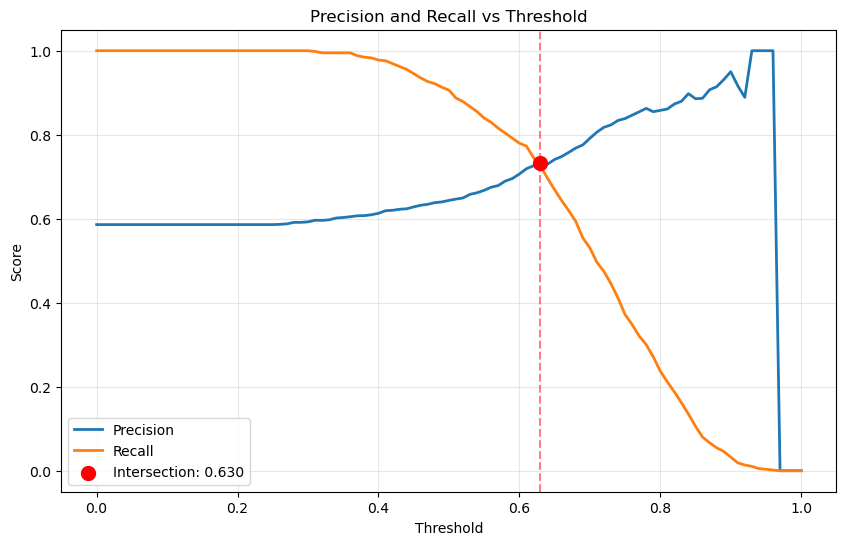

In [63]:
plt.figure(figsize=(10, 6))

plt.plot(thresholds, precisions, label='Precision', linewidth=2)
plt.plot(thresholds, recalls, label='Recall', linewidth=2)

plt.scatter(
    intersection_threshold,
    intersection_precision,
    color='red',
    s=100,
    zorder=5,
    label=f'Intersection: {intersection_threshold:.3f}'
)

plt.axvline(
    intersection_threshold,
    color='red',
    linestyle='--',
    alpha=0.5
)

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


### Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81



In [ ]:
#compute F1 scores

f1_scores = []

f1 = 2 * precision * recall / (precision + recall)


Best threshold: 0.41
Maximum F1: 0.7576


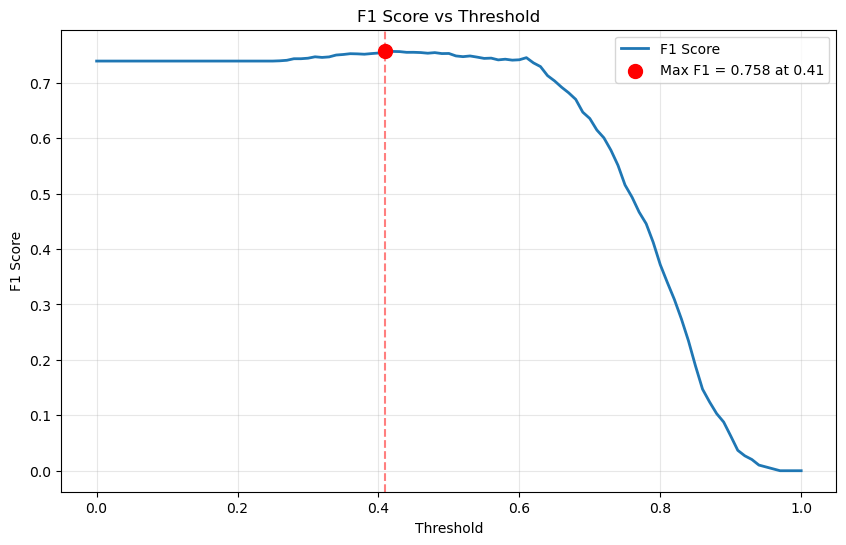

In [69]:
import numpy as np
import matplotlib.pyplot as plt

# Thresholds from 0.00 to 1.00
thresholds = np.arange(0.0, 1.01, 0.01)

f1_scores = []

for p, r in zip(precisions, recalls):
    if p + r == 0:
        f1 = 0
    else:
        f1 = 2 * p * r / (p + r)

    f1_scores.append(f1)

# Find maximum F1
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Best threshold: {best_threshold:.2f}")
print(f"Maximum F1: {best_f1:.4f}")

# Plot
plt.figure(figsize=(10, 6))

plt.plot(
    thresholds,
    f1_scores,
    linewidth=2,
    label='F1 Score'
)

# Mark maximum F1
plt.scatter(
    best_threshold,
    best_f1,
    color='red',
    s=100,
    zorder=5,
    label=f'Max F1 = {best_f1:.3f} at {best_threshold:.2f}'
)

plt.axvline(
    best_threshold,
    color='red',
    linestyle='--',
    alpha=0.5
)

plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 Score vs Threshold')
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()





### Question 5: 5-Fold CV


Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060

In [71]:
from tqdm.auto import tqdm

In [70]:
KFold(n_splits=5, shuffle=True, random_state=1) #into 5 folds 

KFold(n_splits=5, random_state=1, shuffle=True)

In [75]:
df_full_train.iloc[train_idx]

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,paid_ads,technology,student,europe,38757.0,0,0,0.15,0
1,paid_ads,healthcare,self_employed,north_america,56516.0,2,6,0.59,1
2,paid_ads,retail,employed,NA,54963.0,1,0,0.13,0
5,NA,NA,employed,africa,64976.0,4,4,0.54,0
8,referral,manufacturing,unemployed,south_america,21438.0,4,9,0.78,1
...,...,...,...,...,...,...,...,...,...
3995,paid_ads,manufacturing,NA,north_america,66121.0,1,1,0.20,0
3996,paid_ads,manufacturing,employed,north_america,60720.0,4,6,0.69,1
3997,NA,manufacturing,NA,NA,49820.0,2,3,0.44,0
3998,organic_search,manufacturing,self_employed,north_america,52228.0,3,5,0.50,0


In [84]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
import numpy as np

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):

    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    # Convert data to dictionaries
    train_dict = df_train.drop(columns=['converted']).to_dict(orient='records')
    val_dict = df_val.drop(columns=['converted']).to_dict(orient='records')

    # One-hot encode
    dv = DictVectorizer(sparse=True)

    X_train = dv.fit_transform(train_dict)
    X_val = dv.transform(val_dict)

    # Logistic regression
    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )

    model.fit(X_train, y_train)

    # Probability of churn = 1
    y_pred = model.predict_proba(X_val)[:, 1]

    # AUC
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

    print(f"AUC: {auc:.3f}")

print(f"\nMean AUC: {np.mean(scores):.3f}")
print(f"Standard deviation: {np.std(scores):.3f}")




AUC: 0.731
AUC: 0.730
AUC: 0.736
AUC: 0.741
AUC: 0.721

Mean AUC: 0.732
Standard deviation: 0.007


### Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3
  decimal digits).

Which `C` leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest `C`.



In [93]:
from tqdm import tqdm
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


def cross_validate_logistic_regression(
    df,
    target='converted',
    n_splits=5,
    C_values=[0.000001, 0.001, 1]
):
    
    # Separate features and target
    X = df.drop(columns=[target])
    y = df[target]

    kfold = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=1
    )

    results = {}

    for C in tqdm(C_values):

        scores = []

        for train_idx, val_idx in kfold.split(X):

            # Split DataFrame using the fold indices
            X_train_fold = X.iloc[train_idx]
            X_val_fold = X.iloc[val_idx]

            y_train_fold = y.iloc[train_idx]
            y_val_fold = y.iloc[val_idx]

            # Convert DataFrames to dictionaries
            X_train_dict_fold = X_train_fold.to_dict(orient='records')
            X_val_dict_fold = X_val_fold.to_dict(orient='records')

            # One-hot encode
            dv_fold = DictVectorizer(sparse=False)

            X_train_encoded = dv_fold.fit_transform(X_train_dict_fold)
            X_val_encoded = dv_fold.transform(X_val_dict_fold)

            # Train Logistic Regression
            model_fold = LogisticRegression(
                solver='liblinear',
                C=C,
                max_iter=1000
            )

            model_fold.fit(
                X_train_encoded,
                y_train_fold
            )

            # Predict probabilities
            y_pred = model_fold.predict_proba(X_val_encoded)[:, 1]

            # Evaluate
            score = roc_auc_score(
                y_val_fold,
                y_pred
            )

            scores.append(score)

        results[C] = scores

        print(
            f"C={C}: "
            f"mean ROC-AUC={sum(scores) / len(scores):.4f}"
        )

    return results




In [94]:
results = cross_validate_logistic_regression(
    df,
    target='converted',
    n_splits=5
)


 33%|███████████████                              | 1/3 [00:01<00:02,  1.27s/it]

C=1e-06: mean ROC-AUC=0.6176


 67%|██████████████████████████████               | 2/3 [00:01<00:00,  1.08it/s]

C=0.001: mean ROC-AUC=0.7451


100%|█████████████████████████████████████████████| 3/3 [00:02<00:00,  1.25it/s]

C=1: mean ROC-AUC=0.7322


In [95]:
for C, scores in results.items():
    print(
        f"C={C}: "
        f"{sum(scores) / len(scores):.4f} "
        f"+/- {__import__('numpy').std(scores):.4f}"
    )


C=1e-06: 0.6176 +/- 0.0103
C=0.001: 0.7451 +/- 0.0370
C=1: 0.7322 +/- 0.0344
